In [1]:
#loading libraries:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from matplotlib import pyplot as plt

In [2]:
df = pd.read_csv("cardekho.csv")
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0


In [3]:
df.isnull().sum()

year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
seats            221
dtype: int64

In [4]:
df["mileage"] = df["mileage"].fillna(df["mileage"].mean())
df["engine"] = df["engine"].fillna(df["engine"].mean())
df["seats"] = df["seats"].fillna(df["seats"].mean())

In [7]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.drop_duplicates(inplace=True)

In [8]:
#encoding categorical data:
label = LabelEncoder()
df["encoded_fuel"] = label.fit_transform(df["fuel"]) 
var = dict(zip(df["fuel"],df["encoded_fuel"]))
print(var)

df["encoded_seller"] = label.fit_transform(df["seller_type"]) 
var1 = dict(zip(df["seller_type"],df["encoded_seller"]))
print(var1)

df["encoded_trans"] = label.fit_transform(df["transmission"]) 
var2 = dict(zip(df["transmission"],df["encoded_trans"]))
print(var2)

df["encoded_owner"] = label.fit_transform(df["owner"]) 
var3 = dict(zip(df["owner"],df["encoded_owner"]))
print(var3)

{'Diesel': 1, 'Petrol': 3, 'LPG': 2, 'CNG': 0}
{'Individual': 1, 'Dealer': 0, 'Trustmark Dealer': 2}
{'Manual': 1, 'Automatic': 0}
{'First Owner': 0, 'Second Owner': 2, 'Third Owner': 4, 'Fourth & Above Owner': 1, 'Test Drive Car': 3}


In [9]:
df.drop(columns=["fuel","seller_type","transmission","owner"],inplace=True)

In [10]:
#feature selection:
x = df.drop(columns=["selling_price"])
y = df["selling_price"]

In [11]:
#data splitting:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [12]:
#data scaling:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [34]:
#ann architecture:
model = Sequential()
#layer1 = input layer
model.add(Dense(512,activation="sigmoid", input_dim=(9)))

#layer 2:
model.add(Dense(256,activation="relu"))

#layer3:
model.add(Dense(128,activation="relu"))

#layer3:
model.add(Dense(64,activation="relu"))

#layer4: output layer
model.add(Dense(1,activation="linear")) 
model.summary()

#for regression problem activation will be linear and for classiication sigmoid, multi classification softmax 

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                │ (None, 512)            │         5,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 177,665 (694.00 KB)

 Trainable params: 177,665 (694.00 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
#model compilation:
model.compile(optimizer="adam",loss = "mae",metrics=["r2_score"])

In [39]:
#model fit:
hsitory = model.fit(x_train_scaled,y_train, epochs=100,batch_size=32,validation_split=0.2,verbose=1)

Epoch 1/100


139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 149746.3906 - r2_score: 0.5430 - val_loss: 147624.1562 - val_r2_score: 0.5689
Epoch 2/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 149665.0000 - r2_score: 0.5492 - val_loss: 147631.1406 - val_r2_score: 0.5693
Epoch 3/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 149047.1562 - r2_score: 0.5516 - val_loss: 147361.1250 - val_r2_score: 0.5621
Epoch 4/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 148884.5469 - r2_score: 0.5517 - val_loss: 148037.3438 - val_r2_score: 0.5575
Epoch 5/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 148608.0000 - r2_score: 0.5507 - val_loss: 148578.7500 - val_r2_score: 0.5579
Epoch 6/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 148333.0625 - r2_score: 0.5522 - val_loss: 145900.1719 - val_r2_score: 0.5793
Epoch 7/100
139/139 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 148133.3281 - r2_score: 0.5571 - val_loss: 145692.8281 - val_r2_score: 0.5827
Epoch 8/100
139/139 ━━━━━━━━━━━━━━━━━━━

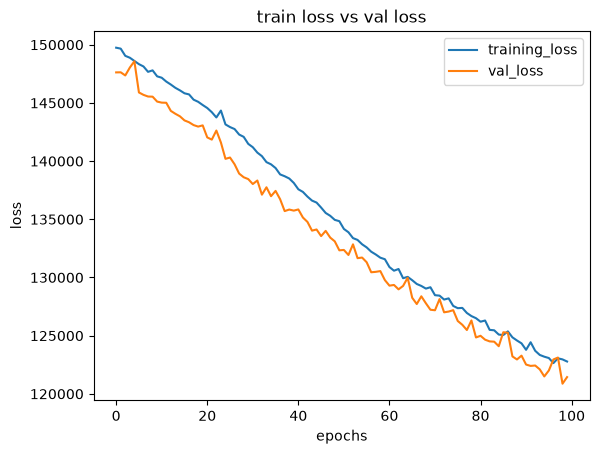

In [40]:
#plot the graphs:
plt.plot(hsitory.history["loss"],label="training_loss")
plt.plot(hsitory.history["val_loss"],label="val_loss")
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("train loss vs val loss")
plt.legend()
plt.show()

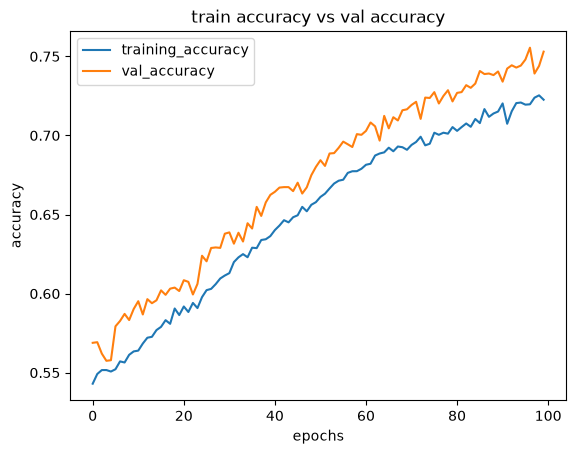

In [41]:
#plot the graphs:
plt.plot(hsitory.history["r2_score"],label="training_accuracy")
plt.plot(hsitory.history["val_r2_score"],label="val_accuracy")
plt.xlabel("epochs")
plt.ylabel("accuracy")
plt.title("train accuracy vs val accuracy")
plt.legend()
plt.show()

In [43]:
#evaluation of model:
test_loss, test_accuracy = model.evaluate(x_test_scaled,y_test)
print("test loss", test_loss)
print("test accuracy",test_accuracy)

44/44 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 114779.5859 - r2_score: 0.7800
test loss 114779.5859375
test accuracy 0.7799520492553711


In [29]:
#the above graphs have so much gap it means it has overfitting and model needs to be refined

# how to reducs the overfitting of the model:
#ann
--> inc number of epochs
--> inc number of nodes
--> inc number of layers
--> dropout
--> batchnormalization
--> activation function change
--> batch size change
--> regularization
--> early stopping use
--> weight initialization
--> loss function change
--> keras tuner
# cnn
--> data augumentation
--> padding
--> pooling layers
--> strides
-->fine tuning
--> keras